# SAE "Analyse automatique de données" -- Notebook 3 : classification multiclasse

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du classifieur choisi (k plus proche voisin ou arbre de décision) pour effectuer une classification multiclasse des avis ;
2. [Bonus] Effectuer des expérimentations supplémentaires avec d'autres classifieurs (l'autre classifieur vu en cours ou d'autres classifieurs de `scikit-learn`) ;
3. Rédiger une synthèse pour justifier des pré-traitements effectués, du choix du regroupement des notes pour obtenir vos classes et des valeurs des paramètres obtenus pour vos classifieurs. Vous concluerez sur le meilleur choix des pré-traitements, des classes binaires et des paramètres de votre ou vos classifieurs.


Faites attention à la prise en compte du déséquilibre que vous pourriez avoir entre vos classes, en termes de nombre d'avis dans chacune des classes. 
Vous pouvez notamment utiliser le module python `imbalanced-learn` pour tester différentes manières de gérer les déséquilibres entre classes.
	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split


## 1. Classification multiclasse avec le classifieur Arbre de décisions

In [10]:
# Le fichier a été téléchargé sur https://huggingface.co/datasets/debojit01/fake-review-dataset/tree/main
fake_review_df = pd.read_csv("data/fake_reviews.csv")

# Affichage des headers
fake_review_df.columns.values.tolist()

['category', 'rating', 'label', 'text_']

In [11]:
# Valeurs nulles
fake_review_df.dropna()


# CG = 0 et OR = 1
fake_review_df.loc[fake_review_df["label"] ==  "CG", "label"] = 0
fake_review_df.loc[fake_review_df["label"] ==  "OR", "label"] = 1

# Assure que la colonne est de type int
fake_review_df['label'] = fake_review_df['label'].astype(int)

"""
Nous avons choisi comme règle: 
- rating >= 3 alors positif sinon négatif

Pour équilibrer le dataframe il est nécessaire d'enlever 24616 lignes, car ce dernier est composé à 80% d'avis positif

5.0    24559
4.0     7965
3.0     3786
2.0     1967
1.0     2155
"""
print(f"Avant équilibrage: {fake_review_df['rating'].value_counts()}")

# Suppression des données 5.0 en trop
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 5.0].sample(n=22592).index,inplace=True)
# Suppression des données 4.0 en trop
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 4.0].sample(n=5998).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 3.0].sample(n=1819).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 1.0].sample(n=188).index,inplace=True)

print(f"Après équilibrage: {fake_review_df['rating'].value_counts()}")

Avant équilibrage: rating
5.0    24559
4.0     7965
3.0     3786
1.0     2155
2.0     1967
Name: count, dtype: int64
Après équilibrage: rating
1.0    1967
3.0    1967
2.0    1967
5.0    1967
4.0    1967
Name: count, dtype: int64


<Axes: title={'center': 'Nombres de mots'}, xlabel='Nombres de mots par avis', ylabel="Nombres d'avis">

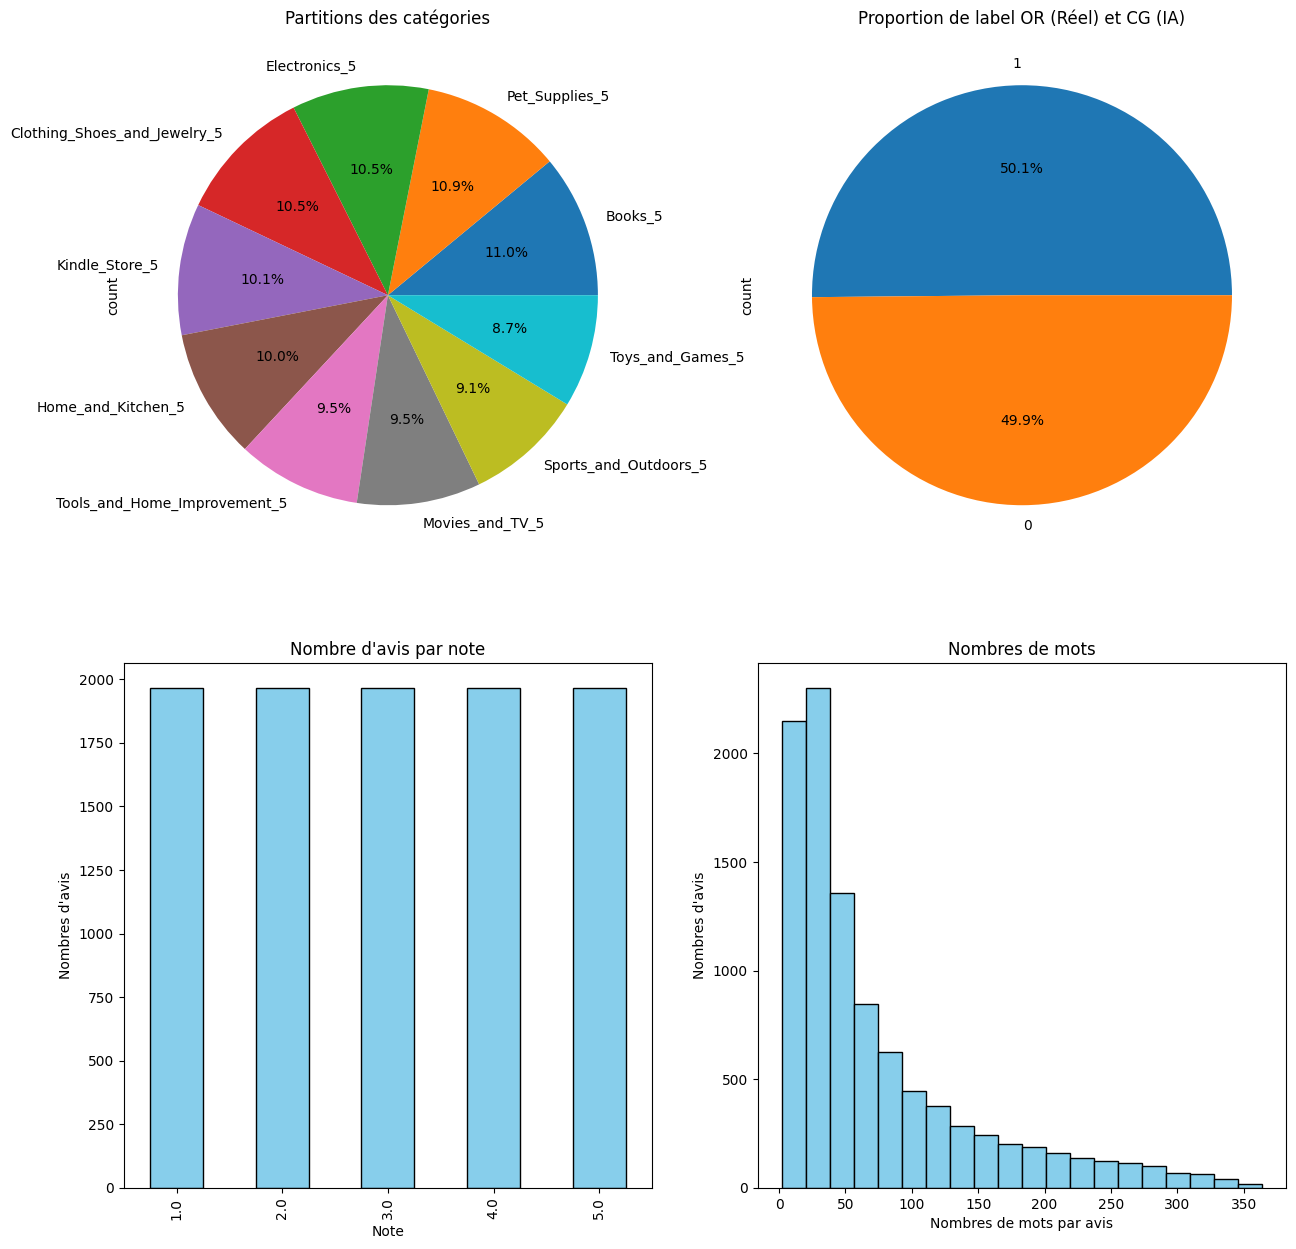

In [12]:
# Visualisation des données d'apprentissage et de tests
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 15))

# Catégories
fake_review_df['category'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0, 0],
    title='Partitions des catégories')

#  Label
fake_review_df['label'].value_counts().plot(kind='pie',
                                            autopct='%1.1f%%',
                                            ax=axes[0, 1],
                                            title='Proportion de label OR (Réel) et CG (IA)')

# Nombre d'avis
fake_review_df['rating'].value_counts().sort_index().plot(kind='bar',
                                                          ax=axes[1, 0],
                                                          color='skyblue',
                                                          edgecolor='black',
                                                          title="Nombre d'avis par note",
                                                          xlabel='Note',
                                                          ylabel="Nombres d'avis")

nb_mots = fake_review_df['text_'].str.split().str.len()
nb_mots.plot(kind='hist',
             bins=20,
             color='skyblue',
             edgecolor='black',
             ax=axes[1, 1],
             title='Nombres de mots',
             xlabel='Nombres de mots par avis',
             ylabel="Nombres d'avis")



In [14]:
X = fake_review_df[['category', 'text_','label']]
y = fake_review_df['rating']

# On isole l'ensemble de train et de validation de l'ensemble de test
X_train_validation, X_test, y_train_validation, y_test = train_test_split(X, y,
                                                    stratify=y,
                                                    # Distribue les données de manière stratifiée = garantit que chaque sous ensemble à la même proportion de rating
                                                    test_size=0.1,
                                                    random_state=42)

# Séparation de l'ensemble de validatiojn
# On prend 1/9 ème des 90% 
X_train, X_val, y_train, y_val = train_test_split(
    X_train_validation, y_train_validation,
    stratify=y_train_validation, 
    test_size=0.111, 
    random_state=42
)
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

# Affichage des différentes métriques
datasets = {
    "Total (Original)": y,
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

print("--- Proportions des notes par ensemble ---")
for name, data in datasets.items():
    proportions = data.value_counts(normalize=True).sort_index() * 100
    
    print(f"\nRépartition dans {name} (en %) :")
    print(proportions.round(2))

Train: 7868 | Validation: 983 | Test: 984
--- Proportions des notes par ensemble ---

Répartition dans Total (Original) (en %) :
rating
1.0    20.0
2.0    20.0
3.0    20.0
4.0    20.0
5.0    20.0
Name: proportion, dtype: float64

Répartition dans Train (en %) :
rating
1.0    19.99
2.0    20.01
3.0    20.01
4.0    19.99
5.0    20.01
Name: proportion, dtype: float64

Répartition dans Validation (en %) :
rating
1.0    20.04
2.0    20.04
3.0    19.94
4.0    20.04
5.0    19.94
Name: proportion, dtype: float64

Répartition dans Test (en %) :
rating
1.0    20.02
2.0    19.92
3.0    20.02
4.0    20.02
5.0    20.02
Name: proportion, dtype: float64


Démarrage de l'optimisation



Meilleurs paramètres trouvés : {'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_split': 2}
Meilleur score de validation (accuracy) : 0.269

Rapport de classification
              precision    recall  f1-score   support

Très Négatif       0.38      0.14      0.20       197
     Négatif       0.20      0.53      0.29       196
      Neutre       0.40      0.15      0.22       197
     Positif       0.25      0.17      0.20       197
Très Positif       0.41      0.40      0.40       197

    accuracy                           0.28       984
   macro avg       0.33      0.28      0.26       984
weighted avg       0.33      0.28      0.26       984



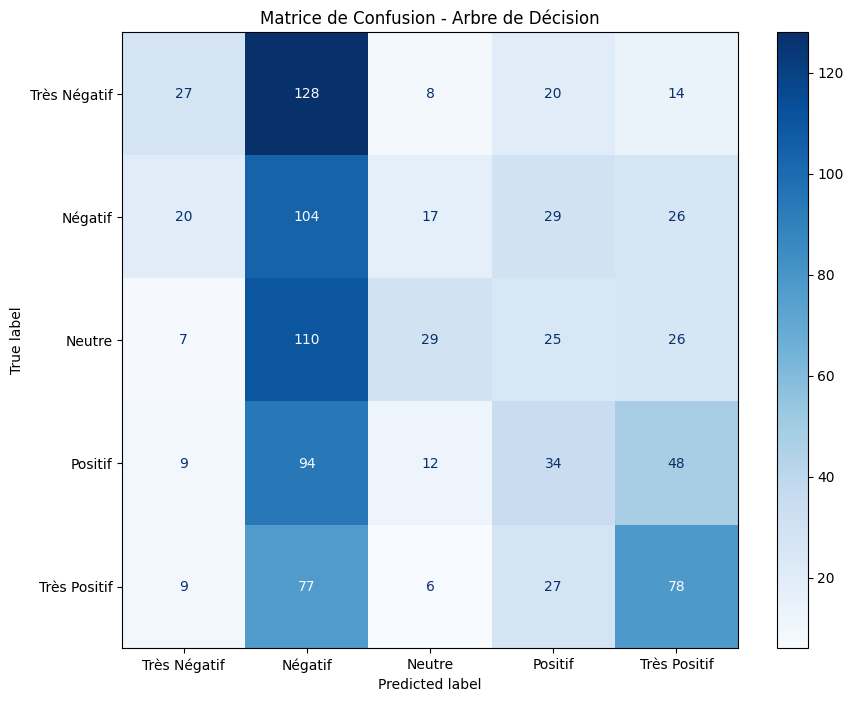

In [ ]:
classes_noms = ['Très Négatif', 'Négatif', 'Neutre', 'Positif', 'Très Positif']

# ------------------------------------ Classifieur Arbre de décisions -----------------------------------

# Transformateurs pour les colonnes
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=2000, stop_words='english'), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ],
    remainder='drop'
)

# Gestion du déséquilibre
pipeline_dt = ImbPipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Grille de paramètres à tester
param_grid_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 10, 20]
}

# Recherche des meilleurs hyperparamètres
print("Démarrage de l'optimisation")
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=3, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)

print(f"\nMeilleurs paramètres trouvés : {grid_dt.best_params_}")
print(f"Meilleur score de validation (accuracy) : {grid_dt.best_score_:.3f}")

# Évaluation sur le jeu de test avec le meilleur modèle
best_dt_model = grid_dt.best_estimator_
predictions_dt = best_dt_model.predict(X_test)

print("\nRapport de classification")
print(classification_report(y_test, predictions_dt, target_names=classes_noms))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_dt, 
    display_labels=classes_noms,
    cmap='Blues',
    ax=ax
)
plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()

## [Bonus] 2. Utilisation d'autres classifieurs multiclasse
 

Démarrage de l'optimisation KNN (peut être long)...
Meilleurs paramètres KNN : {'classifier__metric': 'cosine', 'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}
Meilleur score validation : 0.250

Rapport KNN
              precision    recall  f1-score   support

Très Négatif       0.21      0.30      0.24       216
     Négatif       0.14      0.19      0.16       197
      Neutre       0.26      0.27      0.27       379
     Positif       0.28      0.19      0.23       395
Très Positif       0.31      0.26      0.28       395

    accuracy                           0.24      1582
   macro avg       0.24      0.24      0.24      1582
weighted avg       0.26      0.24      0.25      1582



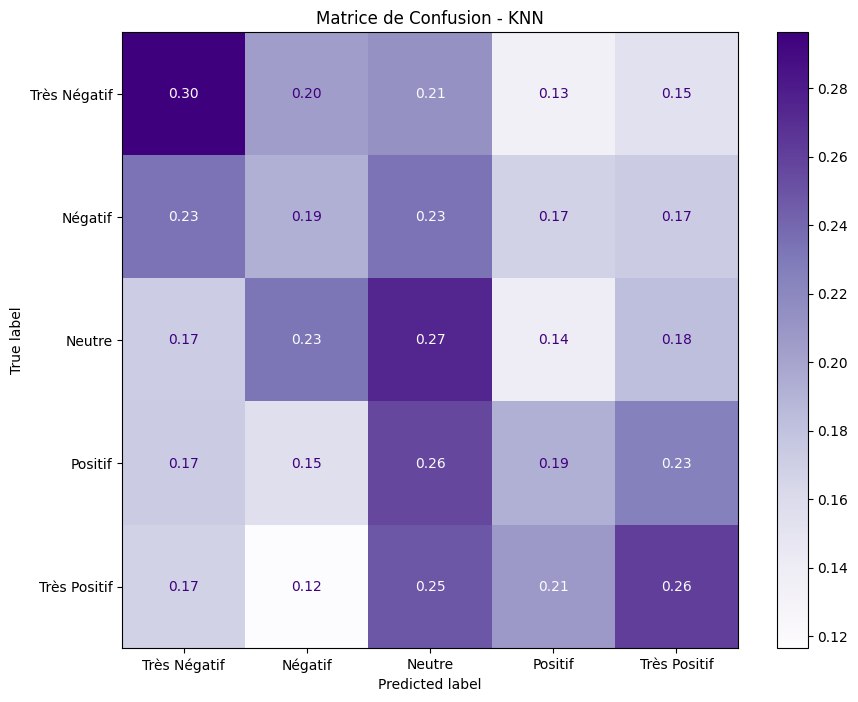

In [3]:
# ------------------------------------ Classifieur KNN -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline KNN ---
pipeline_knn = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', KNeighborsClassifier()) # On configure les paramètres dans la grille
])

# --- Grille ---
param_grid_knn = {
    'classifier__n_neighbors': [5, 11],
    'classifier__weights': ['distance'],
    'classifier__metric': ['cosine']
}

print("Démarrage de l'optimisation KNN (peut être long)...")
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=3, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"Meilleurs paramètres KNN : {grid_knn.best_params_}")
print(f"Meilleur score validation : {grid_knn.best_score_:.3f}")

# --- Résultats ---
best_knn = grid_knn.best_estimator_
pred_knn = best_knn.predict(X_test)

print("\nRapport KNN")
print(classification_report(y_test, pred_knn, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, display_labels=classes_noms, cmap='Purples', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - KNN")
plt.show()

Démarrage de l'optimisation Random Forest...
Meilleurs paramètres RF : {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Meilleur score validation : 0.361

Rapport Random Forest
              precision    recall  f1-score   support

Très Négatif       0.39      0.37      0.38       216
     Négatif       0.19      0.08      0.11       197
      Neutre       0.32      0.34      0.33       379
     Positif       0.32      0.33      0.33       395
Très Positif       0.42      0.53      0.47       395

    accuracy                           0.35      1582
   macro avg       0.33      0.33      0.32      1582
weighted avg       0.34      0.35      0.34      1582



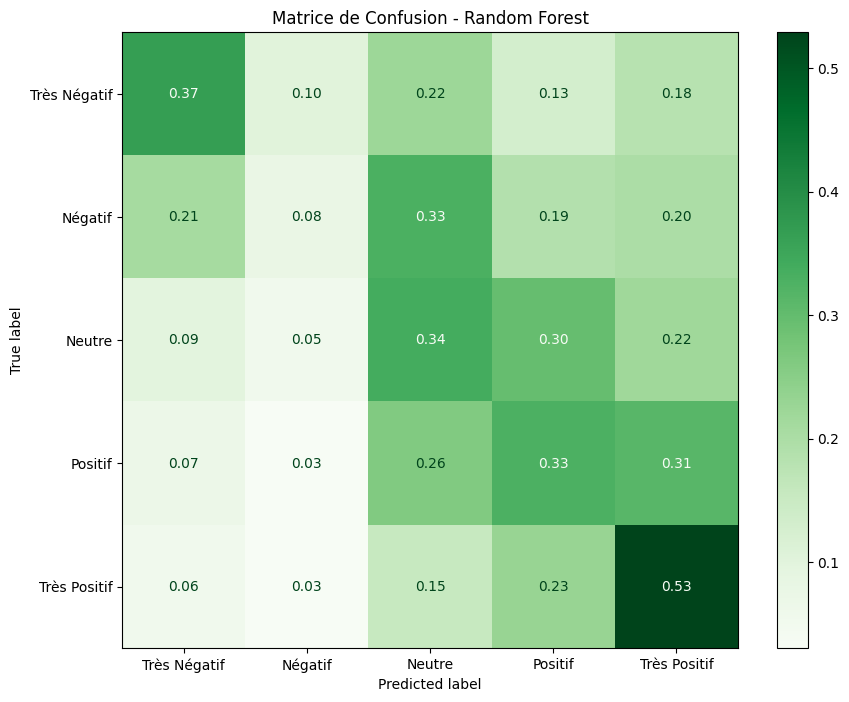

In [4]:
# ------------------------------------ Classifieur Random Forest -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline Random Forest ---
pipeline_rf = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# --- Grille ---
param_grid_rf = {
    'classifier__n_estimators': [100],      # Nombre d'arbres
    'classifier__max_depth': [None, 20],    # Profondeur max (None = apprend tout)
    'classifier__min_samples_leaf': [1, 2]  # Un peu de régularisation
}

print("Démarrage de l'optimisation Random Forest...")
grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print(f"Meilleurs paramètres RF : {grid_rf.best_params_}")
print(f"Meilleur score validation : {grid_rf.best_score_:.3f}")

# --- Résultats ---
best_rf = grid_rf.best_estimator_
pred_rf = best_rf.predict(X_test)

print("\nRapport Random Forest")
print(classification_report(y_test, pred_rf, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, display_labels=classes_noms, cmap='Greens', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Random Forest")
plt.show()

Démarrage de l'optimisation Régression Logistique...
Meilleurs paramètres LogReg : {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Meilleur score validation : 0.343

Rapport Régression Logistique
              precision    recall  f1-score   support

Très Négatif       0.31      0.38      0.34       216
     Négatif       0.23      0.29      0.25       197
      Neutre       0.35      0.28      0.31       379
     Positif       0.32      0.29      0.30       395
Très Positif       0.44      0.45      0.45       395

    accuracy                           0.34      1582
   macro avg       0.33      0.34      0.33      1582
weighted avg       0.34      0.34      0.34      1582



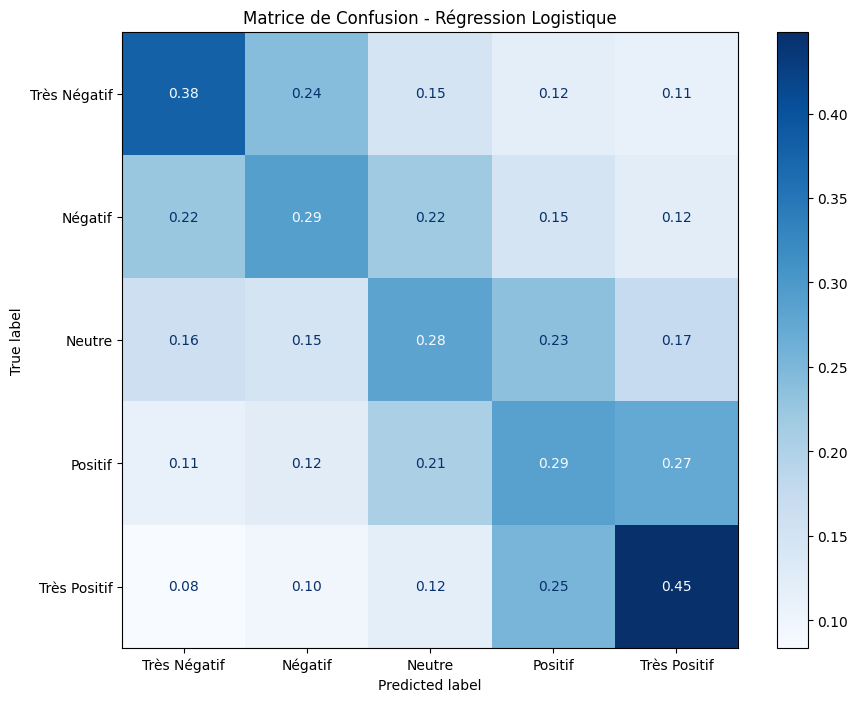

In [5]:
# ------------------------------------ Classifieur LogisticRegression -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline LogReg ---
pipeline_lr = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# --- Grille ---
param_grid_lr = {
    'classifier__C': [0.1, 1, 10],  # Paramètre clé : force de régularisation
    'classifier__solver': ['lbfgs']
}

print("Démarrage de l'optimisation Régression Logistique...")
grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print(f"Meilleurs paramètres LogReg : {grid_lr.best_params_}")
print(f"Meilleur score validation : {grid_lr.best_score_:.3f}")

# --- Résultats ---
best_lr = grid_lr.best_estimator_
pred_lr = best_lr.predict(X_test)

print("\nRapport Régression Logistique")
print(classification_report(y_test, pred_lr, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=classes_noms, cmap='Blues', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Régression Logistique")
plt.show()

## 3. Synthèse des expérimentations et des résultats obtenus